# 1. Exploratory data analysis

I start with the Cleveland subset of the UCI Heart Disease dataset. The notebook reads the cleaned CSV in `data/heart_cleaned.csv`, which is included in the repository, so the analysis can run without downloading the source again. Keeping the exploratory work separate from model training makes it easier to inspect the data before choosing a pipeline.


In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
%matplotlib inline
print("working dir:", Path.cwd())

working dir: C:\Users\Dinesh\Downloads\heart-mlops-submission\heart-mlops-final


In [2]:
from src.download_data import clean, COLUMNS
df = pd.read_csv('data/heart_cleaned.csv')
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cleaning rules

The original file uses `?` when a value is missing. The cleaning function converts those markers to `NaN` and changes the original 0-4 disease-severity label into a binary target: 0 means no disease recorded and any value above 0 means disease is present. That matches the assignment’s binary-classification objective. I keep missing values in the cleaned file and let the training pipeline handle imputation so the imputation values are learned from training folds, not from the full dataset.


In [3]:
raw = pd.DataFrame([[63,1,1,145,233,1,2,150,0,2.3,3,'0.0','6.0',0],
                    [67,1,4,160,286,0,2,108,1,1.5,2,'?','3.0',2]], columns=COLUMNS)
clean(raw)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,NaN,3.0,1


## Missing values and class balance

There are six missing cells in total: four in `ca` and two in `thal`. The target classes are reasonably balanced (164 records in class 0 and 139 in class 1), so I did not apply over-sampling or under-sampling. Accuracy is still useful to report, but I also check precision, recall, and ROC-AUC later because no single metric tells the whole story.


In [4]:
print(df.isna().sum()[lambda s: s > 0])
print(df['target'].value_counts().rename({0: 'no disease', 1: 'disease'}))
print((df['target'].value_counts(normalize=True)*100).round(1))

ca      4
thal    2
dtype: int64
target
no disease    164
disease       139
Name: count, dtype: int64
target
0    54.1
1    45.9
Name: proportion, dtype: float64


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## Distributions

I compare numeric feature distributions by target class to look for visible differences and unusual values. These plots are useful for forming questions and spotting data-quality issues; by themselves, they do not prove that a feature causes heart disease.


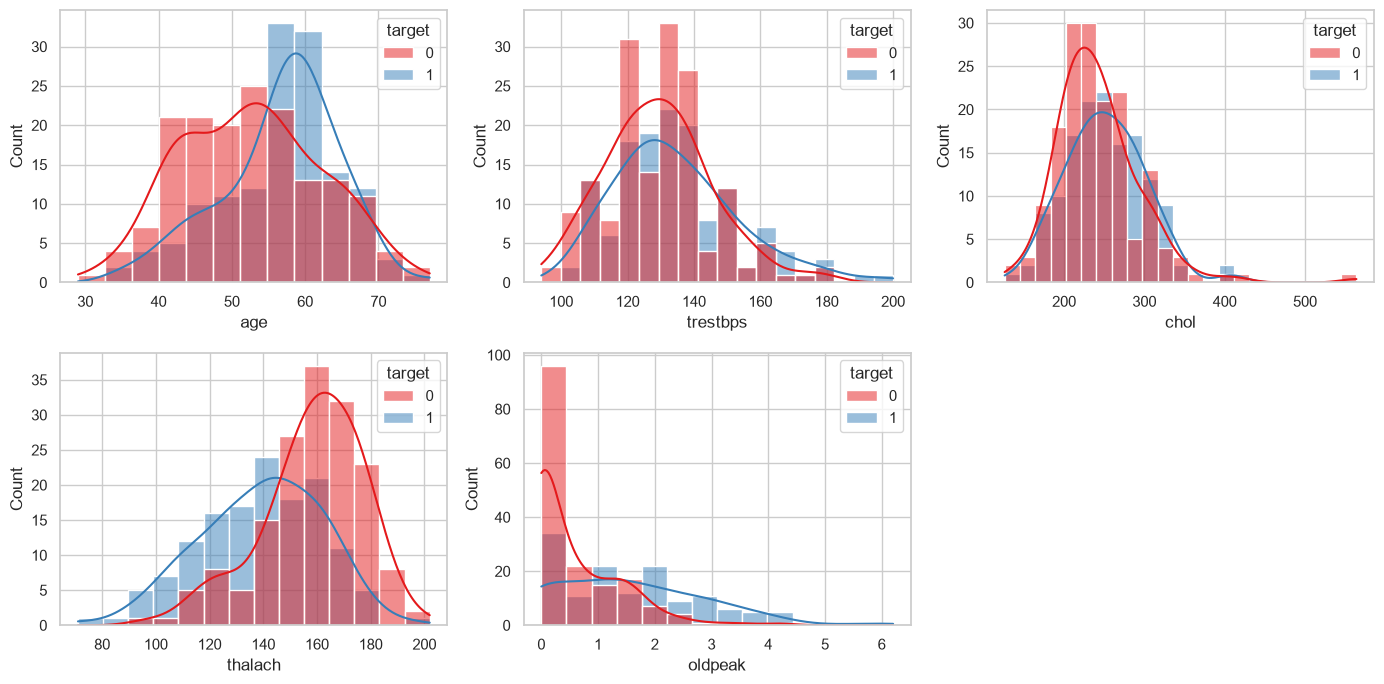

In [6]:
num = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num):
    sns.histplot(data=df, x=c, hue='target', kde=True, ax=ax, palette='Set1')
axes.ravel()[-1].axis('off')
fig.tight_layout(); plt.show()

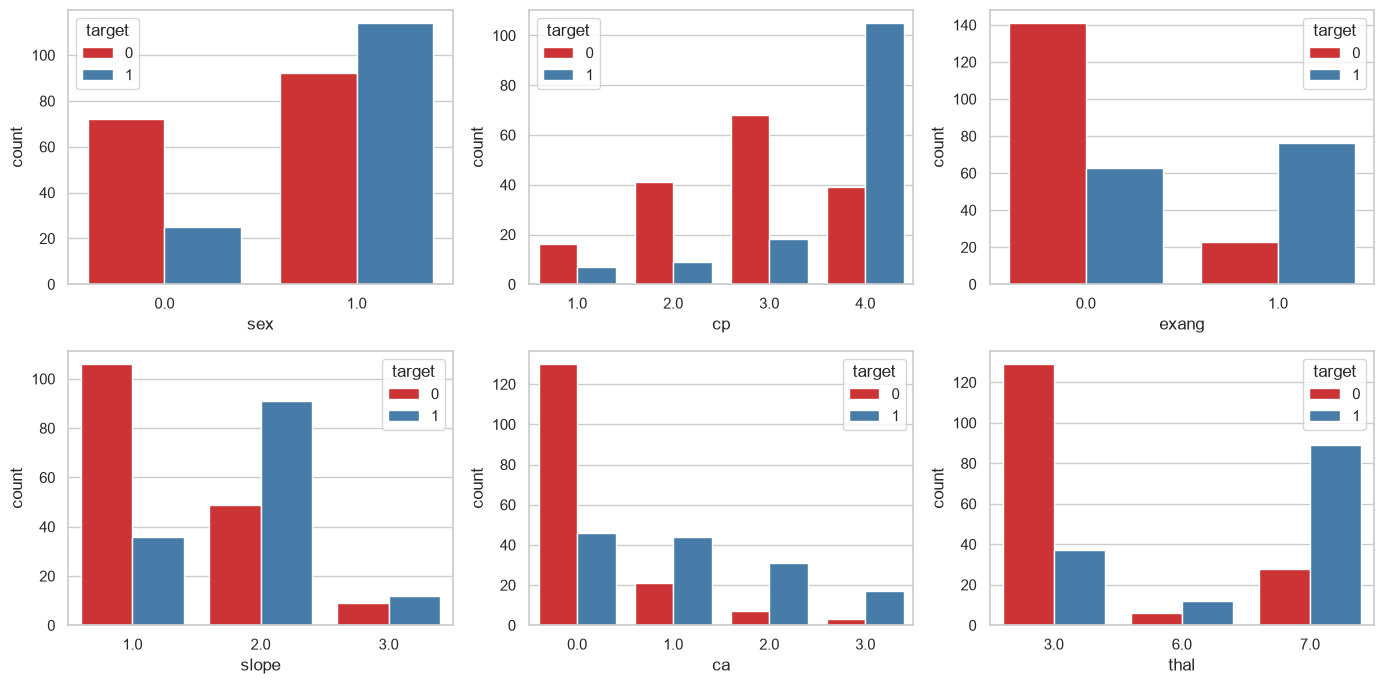

In [7]:
cats = ['sex', 'cp', 'exang', 'slope', 'ca', 'thal']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), cats):
    sns.countplot(data=df, x=c, hue='target', ax=ax, palette='Set1')
fig.tight_layout(); plt.show()

## Correlations

The correlation heatmap gives a quick view of pairwise linear relationships. I use it as a descriptive check rather than as an automatic feature-selection rule, since several features are categorical codes and a simple correlation cannot capture every type of relationship.


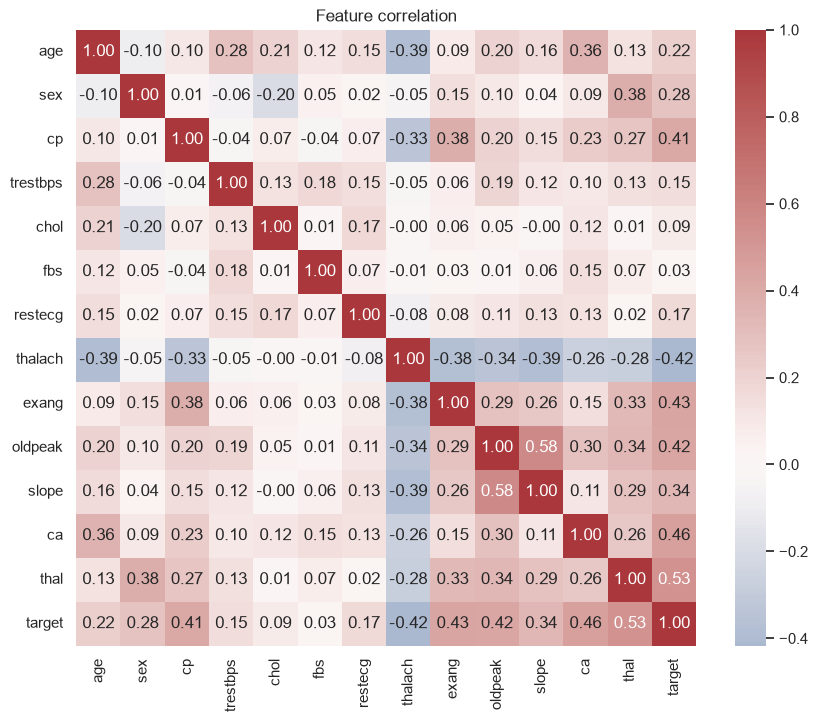

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Feature correlation'); plt.show()

In [9]:
df.corr()['target'].drop('target').sort_values(ascending=False).round(3)

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
thalach    -0.417
Name: target, dtype: float64

## Engineered feature: `hr_reserve`

I added `hr_reserve = thalach / (220 - age)` to express the recorded maximum heart rate as a fraction of a simple age-based estimate. The idea is to make heart-rate values a little easier to compare across ages. This is only a feature-engineering experiment for the assignment, not a clinically validated formula.


thalach      -0.417
hr_reserve   -0.359
target        1.000
Name: target, dtype: float64


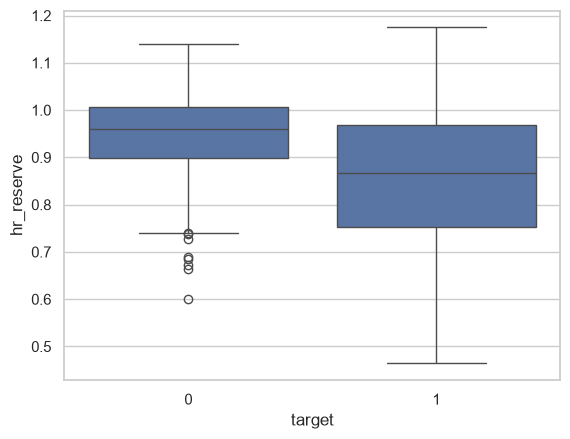

In [10]:
from src.features import add_hr_reserve
d = add_hr_reserve(df)
print(d[['thalach', 'hr_reserve', 'target']].corr()['target'].round(3))
sns.boxplot(data=d, x='target', y='hr_reserve'); plt.show()

**What stood out to me:** the two target classes are close enough in size that I did not need resampling. In this dataset, `thal`, `ca`, `exang`, `oldpeak`, `cp`, and `thalach` show more signal than `fbs` or `chol`. Only six cells are missing, and the pipeline’s median/most-frequent imputers are sufficient to handle them without discarding rows. These patterns describe this dataset; they should not be interpreted as medical advice or causal findings.
